# Task 3 — Midterm Project: Bank Marketing
Student: Smakov Danieldiaz · SEED: 3194 (last 4 digits of student ID)

In [2]:
import re
import sys
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd

SEED = 3194

print("Python:", sys.version.split()[0])
with open("requirements.txt") as f:
    for line in f:
        name = re.split(r"[=<>!~\[; ]", line.strip())[0]
        if name and not name.startswith("#"):
            try:
                print(f"  {name:20s} {version(name)}")
            except PackageNotFoundError:
                print(f"  {name:20s} NOT INSTALLED")

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("\ntrain:", train.shape, "| test:", test.shape)
print("Только в train:", sorted(set(train.columns) - set(test.columns)))
print("Только в test :", sorted(set(test.columns) - set(train.columns)))
print("\nКолонки train:", list(train.columns))

Python: 3.12.5
  numpy                2.3.4
  scipy                1.16.3
  pandas               2.3.3
  matplotlib           3.10.7
  scikit-learn         1.7.2
  joblib               1.5.2

train: (32940, 22) | test: (8236, 20)
Только в train: ['duration', 'y']
Только в test : []

Колонки train: ['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [3]:
train.head()

,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## Stage 1. Framing

The bank calls clients to sell a term deposit. For each client I need to predict how likely they are to say yes, and this has to happen before the call is made.

The call centre can only call 10% of the list. So in practice the model is used to rank clients: sort them by score and call the top 10%. Because of that, accuracy and the usual 0.5 threshold don't really matter here. What matters is how many "yes" clients end up in that top 10%.

To compare models I use average precision (area under the precision-recall curve) as the main metric. The data is imbalanced, only about 11% say yes, and AP pays more attention to the top of the ranking than ROC-AUC does. I also report ROC-AUC, since the hidden test set is scored with it. At the end I check precision, recall and lift for the top 10% on my hold-out.

The train and test files don't have the same columns. test.csv has no y, which is expected, but it also has no duration. Duration is how long the call lasted, so it's only known after the call is over. It's strongly linked to the answer (a short call almost always means no), but we score clients before calling them, so we won't have it at prediction time. If I used it, the model would look great in validation but be useless in reality. This is data leakage, so I drop duration. I also drop id, because it's just a row number.

## Stage 2 · Understanding the data

In [4]:
y_all = (train["y"] == "yes").astype(int)

print(train["y"].value_counts())
print(f"\nShare of 'yes': {y_all.mean():.4f}")
print(f"Accuracy of always predicting 'no': {1 - y_all.mean():.4f}")

y
no     29229
yes     3711
Name: count, dtype: int64

Share of 'yes': 0.1127
Accuracy of always predicting 'no': 0.8873


In [5]:
print("Real NaN in train:", train.isna().sum().sum(), "| in test:", test.isna().sum().sum())

cat_cols = [c for c in train.select_dtypes("object").columns if c != "y"]
num_cols = [c for c in train.columns if c not in cat_cols + ["id", "y", "duration"]]
print("\nCategorical:", cat_cols)
print("Numeric    :", num_cols)

unknown = pd.DataFrame({
    "train_count": (train[cat_cols] == "unknown").sum(),
    "train_share": (train[cat_cols] == "unknown").mean().round(4),
    "test_count":  (test[cat_cols] == "unknown").sum(),
})
print("\n'unknown' per categorical column:")
print(unknown[unknown["train_count"] > 0])

n999 = (train["pdays"] == 999).sum()
print(f"\npdays == 999: {n999} rows ({n999 / len(train):.4f} of train)")
print("\npdays==999 vs poutcome:")
print(pd.crosstab(train["pdays"] == 999, train["poutcome"]))
print("\npdays==999 vs previous == 0:")
print(pd.crosstab(train["pdays"] == 999, train["previous"] == 0))

print("\ndefault value counts:")
print(train["default"].value_counts())

Real NaN in train: 0 | in test: 0

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric    : ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

'unknown' per categorical column:
           train_count  train_share  test_count
job                275       0.0083          55
marital             64       0.0019          16
education         1401       0.0425         329
default           6871       0.2086        1725
housing            794       0.0241         196
loan               794       0.0241         196

pdays == 999: 31694 rows (0.9622 of train)

pdays==999 vs poutcome:
poutcome  failure  nonexistent  success
pdays                                  
False         116            0     1130
True         3248        28446        0

pdays==999 vs previous == 0:
previous  False  True 
pdays                 
False      1246      0
True       

In [6]:
from scipy.stats import spearmanr

print("First 20 months by id:", train.sort_values("id")["month"].head(20).tolist())
for col in ["euribor3m", "nr.employed", "emp.var.rate"]:
    rho, _ = spearmanr(train["id"], train[col])
    print(f"Spearman(id, {col}) = {rho:+.3f}")

First 20 months by id: ['may', 'aug', 'aug', 'may', 'jun', 'aug', 'may', 'apr', 'jul', 'nov', 'nov', 'sep', 'aug', 'jul', 'aug', 'nov', 'may', 'apr', 'jun', 'jun']
Spearman(id, euribor3m) = -0.002
Spearman(id, nr.employed) = -0.002
Spearman(id, emp.var.rate) = -0.001


In [7]:
print("poutcome vs previous == 0:")
print(pd.crosstab(train["poutcome"], train["previous"] == 0))

both = ((train["housing"] == "unknown") & (train["loan"] == "unknown")).sum()
print(f"\nhousing and loan both 'unknown': {both} rows")

print("\nShare of 'yes' by category (does 'unknown' behave differently?):")
for col in ["default", "education", "job"]:
    t = y_all.groupby(train[col]).agg(yes_rate="mean", count="count").round(3)
    print(f"\n{col}:\n{t}")

poutcome vs previous == 0:
previous     False  True 
poutcome                 
failure       3364      0
nonexistent      0  28446
success       1130      0

housing and loan both 'unknown': 794 rows

Share of 'yes' by category (does 'unknown' behave differently?):

default:
         yes_rate  count
default                 
no          0.129  26067
unknown     0.052   6871
yes         0.000      2

education:
                     yes_rate  count
education                           
basic.4y                0.101   3372
basic.6y                0.083   1800
basic.9y                0.077   4855
high.school             0.109   7591
illiterate              0.286     14
professional.course     0.116   4155
university.degree       0.137   9752
unknown                 0.144   1401

job:
               yes_rate  count
job                           
admin.            0.131   8398
blue-collar       0.070   7393
entrepreneur      0.085   1185
housemaid         0.098    861
management        0.114  

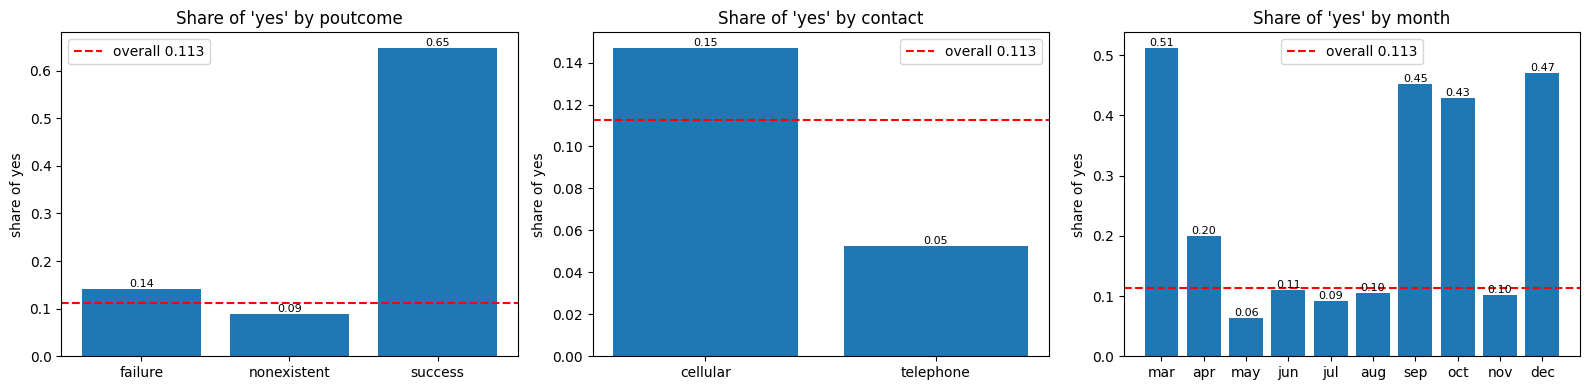


poutcome:
             yes_rate  count
poutcome                    
failure         0.140   3364
nonexistent     0.088  28446
success         0.648   1130

contact:
           yes_rate  count
contact                   
cellular      0.147  20946
telephone     0.053  11994

month:
       yes_rate  count
month                 
apr       0.200   2089
aug       0.104   4937
dec       0.469    147
jul       0.091   5820
jun       0.110   4249
mar       0.512    457
may       0.064  10942
nov       0.103   3287
oct       0.429    559
sep       0.453    453


In [8]:
import matplotlib.pyplot as plt

month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    t = y_all.groupby(train[col]).agg(yes_rate="mean", count="count")
    if col == "month":
        t = t.reindex(month_order)
    bars = ax.bar(t.index, t["yes_rate"])
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in t["yes_rate"]], fontsize=8)
    ax.axhline(y_all.mean(), color="red", linestyle="--", label=f"overall {y_all.mean():.3f}")
    ax.set_title(f"Share of 'yes' by {col}")
    ax.set_ylabel("share of yes")
    ax.legend()
plt.tight_layout()
plt.show()

for col in ["poutcome", "contact", "month"]:
    t = y_all.groupby(train[col]).agg(yes_rate="mean", count="count").round(3)
    print(f"\n{col}:\n{t}")

Single-feature ROC-AUC (strength = max(auc, 1-auc)):
       feature   auc  strength
   nr.employed 0.250     0.750
     euribor3m 0.255     0.745
  emp.var.rate 0.283     0.717
      previous 0.610     0.610
cons.price.idx 0.391     0.609
         pdays 0.401     0.599
      campaign 0.447     0.553
 cons.conf.idx 0.542     0.542
           age 0.491     0.509


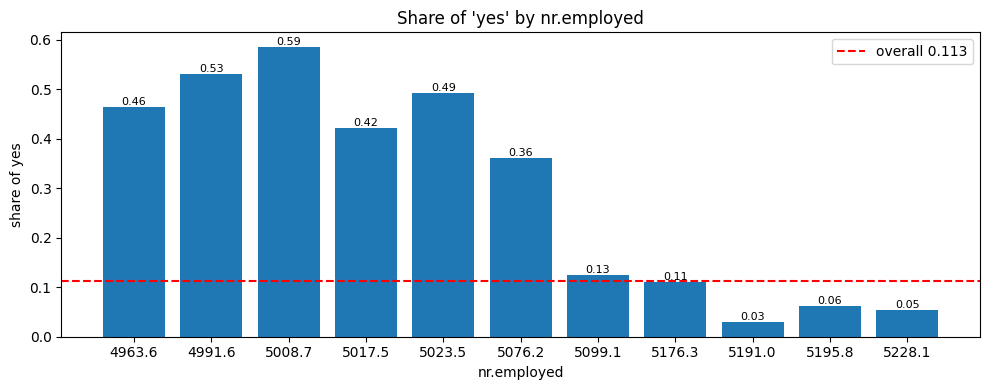

             yes_rate  count
nr.employed                 
4963.6          0.463    512
4991.6          0.530    619
5008.7          0.585    528
5017.5          0.421    862
5023.5          0.493    138
5076.2          0.360   1349
5099.1          0.125   6786
5176.3          0.111      9
5191.0          0.030   6174
5195.8          0.062   2925
5228.1          0.054  13038


In [9]:
from sklearn.metrics import roc_auc_score

rows = []
for col in num_cols:
    auc = roc_auc_score(y_all, train[col])
    rows.append({"feature": col, "auc": round(auc, 3), "strength": round(max(auc, 1 - auc), 3)})
num_strength = pd.DataFrame(rows).sort_values("strength", ascending=False)
print("Single-feature ROC-AUC (strength = max(auc, 1-auc)):")
print(num_strength.to_string(index=False))

t = y_all.groupby(train["nr.employed"]).agg(yes_rate="mean", count="count")
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(t.index.astype(str), t["yes_rate"])
ax.bar_label(bars, labels=[f"{v:.2f}" for v in t["yes_rate"]], fontsize=8)
ax.axhline(y_all.mean(), color="red", linestyle="--", label=f"overall {y_all.mean():.3f}")
ax.set_title("Share of 'yes' by nr.employed")
ax.set_xlabel("nr.employed")
ax.set_ylabel("share of yes")
ax.legend()
plt.tight_layout()
plt.show()
print(t.round(3))

### What I found so far

Class balance. Only 3711 of 32940 clients said yes (11.3%). A model that always says "no" already gets 88.7% accuracy, so accuracy tells almost nothing on this data.

Missing values. There are no real NaN values, missing values are written as "unknown" instead. Counts in train: default 6871 (20.9%), education 1401 (4.3%), housing 794, loan 794, job 275, marital 64. Housing and loan are unknown in exactly the same 794 rows, so it's probably one missing source. For default, "unknown" doesn't look random: these clients say yes only 5.2% of the time, compared to 12.9% for "no". Also default = "yes" appears only 2 times, so this column is basically "no" vs "unknown". Because of this I don't want to just fill "unknown" with the most common value. I keep it as its own category and check this choice with CV later.

Sentinel. pdays = 999 is not a real number of days, it means "no previous contact recorded". It's in 31694 rows (96.2%). If I leave it as a number, 999 looks like a huge value, which messes up scaling and distance-based models like KNN and SVM. One thing I noticed: 999 doesn't exactly mean "never contacted". poutcome = nonexistent matches previous = 0 exactly (28446 rows), but there are also 3248 rows with pdays = 999 and poutcome = failure. These clients were contacted before, pdays just wasn't recorded for them. So I handle pdays separately: replace 999 with a normal value and add a 0/1 flag column for it.

Row order. The original UCI file is sorted by date, but here the rows are shuffled: the Spearman correlation between id and euribor3m, nr.employed, emp.var.rate is about 0 (-0.002). So the row order has no meaning and a normal stratified random split is fine. But there is no year column, and month plus the economic indicators basically tell which period the call was made in. I come back to this in Stage 7.

### Which features are related to the answer

poutcome is the strongest category. Clients for whom the previous campaign was a success say yes 64.8% of the time (1130 clients), compared to 11.3% overall and 8.8% for clients who were never contacted before.

contact: cellular 14.7% yes vs telephone 5.3%, almost 3 times more.

month: May had the most calls (10942) and the lowest yes rate (6.4%). In March, September, October and December the yes rate is 43-51%, but there were few calls in those months (147-559). This looks more like a difference between time periods than something about the month itself.

For numeric features I computed the ROC-AUC of each feature on its own. The strongest are the economic indicators: nr.employed 0.75, euribor3m 0.745, emp.var.rate 0.717 (their AUC is below 0.5, which means lower values go with more yes). On the plot, when nr.employed is 5076 or lower the yes rate is 36-59%, and when it's 5191 or higher it's only 3-6%. Next come previous (0.61) and pdays (0.60). campaign is weak (0.553): more calls in this campaign means a bit fewer yes. age is almost 0.5 (0.509), but this AUC only catches a "more = better" type of relation, and age can matter in a non-linear way (for example job = student has 30.5% yes).

The economic indicators are known before the call, so I can use them. But they describe the general situation in a period, not the client. If the economy changes, the model may work worse than it does here.